In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
samplesheet = pd.read_csv("/g/korbel/hain/centromere/samplesheets/centromeres_full.active.length.cluster.tsv", sep="\t")
samplesheet.head()

,SAMPLE,ASM,HP,PROJECT,CHROM,CENT_FASTA_PATH,NUM_CONTIGS,CONTIG_LENGTH,FAMILY,FAMILYSTATE,SUPERPOP,POP,ID,ACTIVE,UNSTABLE,HOR_LENGTH,HOR_SPAN,ARCHITECTURE
0,CHM1,T2T,HP1,T2T,chr21,/scratch/hain/centromere/centromeres/chr21_CHM...,1,1819674,NaN,NaN,EAS,NaN,CHM1_HP1_T2T_T2T,True,False,1176502,1228355,chr21_968
1,HG04204,HPRC,HP2,HPRC2,chr3,/scratch/hain/centromere/centromeres/chr3_HG04...,1,5273549,ST006,child,SAS,STU,HG04204_HP2_HPRC_HPRC2,True,False,2140104,4006938,chr3_1009
2,HG03704,HPRC,HP2,HPRC2,chr2,/scratch/hain/centromere/centromeres/chr2_HG03...,1,4968267,PK60,child,SAS,PJL,HG03704_HP2_HPRC_HPRC2,True,False,2180995,2214651,chr2_929
3,HG00731,VERKKO,HP2,HGSVC,chr20,/scratch/hain/centromere/centromeres/chr20_HG0...,1,7316426,PR05,father,AMR,PUR,HG00731_HP2_VERKKO_HGSVC,True,False,2445974,5672092,chr20_1081
4,HG03369,HPRC,HP2,HPRC2,chr4,/scratch/hain/centromere/centromeres/chr4_HG03...,1,4918950,NG98,mother,AFR,ESN,HG03369_HP2_HPRC_HPRC2,True,False,3413929,3677878,chr4_1075


In [3]:
col_eur_vs_noneur = []
for _, row in samplesheet.iterrows():
    if row["SUPERPOP"] == "EUR":
        col_eur_vs_noneur.append("EUR")
    else:
        col_eur_vs_noneur.append("Non-EUR")

samplesheet["EUR_vs_NonEUR"] = col_eur_vs_noneur

In [4]:
chromosomes = [f"chr{x}" for x in range(1, 23)]

In [5]:
chromosomes = [ 'chr1',  'chr3',  'chr4',  'chr5',  'chr6',  'chr7',  'chr8',  'chr9',
 'chr10', 'chr11', 'chr12', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20']

In [6]:
samplesheet = samplesheet[samplesheet["CHROM"].isin(chromosomes)]

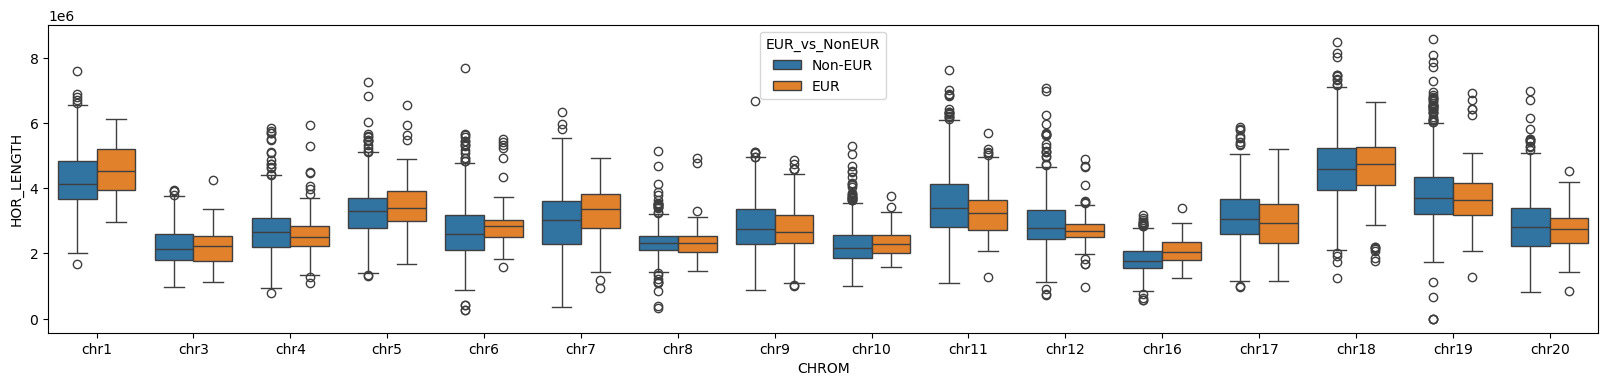

In [7]:
fig, ax = plt.subplots(figsize=(20, 4))
sns.boxplot(
    data=samplesheet,
    x="CHROM",
    y="HOR_LENGTH",
    hue="EUR_vs_NonEUR",
    order=chromosomes,
)
plt.show()

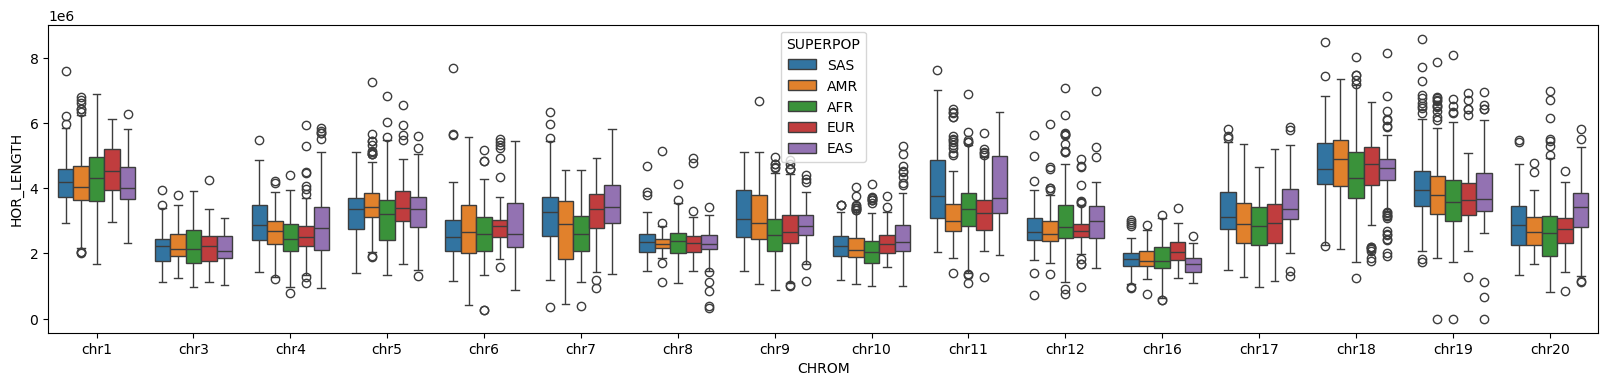

In [8]:
fig, ax = plt.subplots(figsize=(20, 4))
sns.boxplot(
    data=samplesheet,
    x="CHROM",
    y="HOR_LENGTH",
    hue="SUPERPOP",
    order=chromosomes
)
plt.show()

In [9]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

plot_df = (
    samplesheet[~pd.isna(samplesheet["HOR_LENGTH"])]
    .groupby(["CHROM", "SUPERPOP"])["HOR_LENGTH"]
    .agg(MEAN="mean", MEDIAN="median", STD="std", IQR=iqr)
    .reset_index()
)

plot_df["NORM_STD"] = plot_df["STD"] / plot_df["MEAN"]
plot_df["NORM_IQR"] = plot_df["IQR"] / plot_df["MEDIAN"]

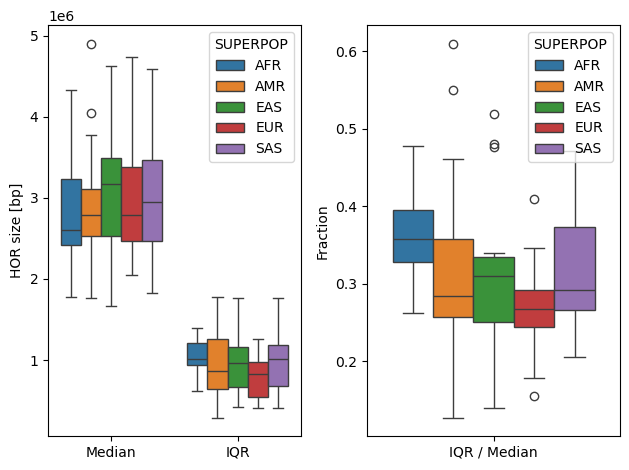

In [10]:
ax1 = plt.subplot(1, 2, 1)
ax2 = plt.subplot(1, 2, 2)

sns.boxplot(
    pd.melt(plot_df, id_vars=["SUPERPOP"], value_vars=["MEDIAN", "IQR"]),
    x="variable",
    y="value",
    hue="SUPERPOP",
    ax=ax1
)

sns.boxplot(
    pd.melt(plot_df, id_vars=["SUPERPOP"], value_vars=["NORM_IQR"]),
    x="variable",
    y="value",
    hue="SUPERPOP",
    ax=ax2
)

ax1.set_ylabel("HOR size [bp]")
ax1.set_xticks([0, 1], ["Median", "IQR"])
ax2.set_ylabel("Fraction")
ax1.set_xlabel("")
ax2.set_xlabel("")
ax2.set_xticks([0], ["IQR / Median"])

plt.tight_layout()

plt.show()

In [44]:
plot_df[plot_df["SUPERPOP"] == "EUR"]["IQR"].median()

np.float64(826024.5)

In [12]:
plot_df[plot_df["SUPERPOP"] == "EUR"]["NORM_IQR"].median()

np.float64(0.2679503883886587)

#### Calculate iqr of "common" architectures
- cutoff is more than 10 haplotypes

In [37]:
arch_hor_length_data = []

for chrom, chrom_df in samplesheet.groupby("CHROM"):
    if not chrom in chromosomes:
        continue
    arch_hor_length_data.append({
            "CHROM": chrom,
            "GROUP": "all",
            "ARCHITECTURE": chrom,
            "MEDIAN_HOR_LENGTH": chrom_df["HOR_LENGTH"].median(),
            "IQR_HOR_LENGTH": chrom_df["HOR_LENGTH"].quantile(0.75) - chrom_df["HOR_LENGTH"].quantile(0.25)
        })    
    for arch, arch_df in chrom_df.groupby("ARCHITECTURE"):
        
        # skip small architectures
        if arch_df.shape[0] < 10:
            continue

        arch_hor_length_data.append({
            "CHROM": chrom,
            "GROUP":"arch",
            "ARCHITECTURE": arch,
            "MEDIAN_HOR_LENGTH": arch_df["HOR_LENGTH"].median(),
            "IQR_HOR_LENGTH": arch_df["HOR_LENGTH"].quantile(0.75) - arch_df["HOR_LENGTH"].quantile(0.25)
        })
hor_length_plot_df = pd.DataFrame(arch_hor_length_data)

In [39]:
hor_length_plot_df[hor_length_plot_df["GROUP"] == "all"]["MEDIAN_HOR_LENGTH"].median()

np.float64(2764494.0)

In [40]:
hor_length_plot_df[hor_length_plot_df["GROUP"] == "all"]["IQR_HOR_LENGTH"].median()

np.float64(1025332.375)

In [43]:
hor_length_plot_df["RATIO"] = hor_length_plot_df["IQR_HOR_LENGTH"] / hor_length_plot_df["MEDIAN_HOR_LENGTH"]
hor_length_plot_df[hor_length_plot_df["GROUP"] == "all"]["RATIO"].median()

np.float64(0.3213658066441199)

In [45]:
hor_length_plot_df[~(hor_length_plot_df["GROUP"] == "all")]["IQR_HOR_LENGTH"].median()

np.float64(648869.0)

In [46]:
hor_length_plot_df[~(hor_length_plot_df["GROUP"] == "all")]["RATIO"].median()

np.float64(0.237387302536249)

In [85]:
D_stat = []
for chrom, chrom_df in samplesheet.groupby("CHROM"):
    if not chrom in chromosomes:
        continue
    for sample, sample_df in chrom_df.groupby("SAMPLE"): 
        if sample_df.shape[0] != 2:
            continue
        ### difference between HOR size of haplotypes divided by mean HOR size
        D = np.abs(sample_df["HOR_LENGTH"].values[0] - sample_df["HOR_LENGTH"].values[1]) / sample_df["HOR_LENGTH"].mean()
        gt = "HET"
        if sample_df["ARCHITECTURE"].values[0] == sample_df["ARCHITECTURE"].values[1]:
            gt = "HOM"
        D_stat.append({"D": D, "GT": gt, "SPOP":sample_df["SUPERPOP"].values[0]})
D_df = pd.DataFrame(D_stat)

<Axes: xlabel='GT', ylabel='D'>

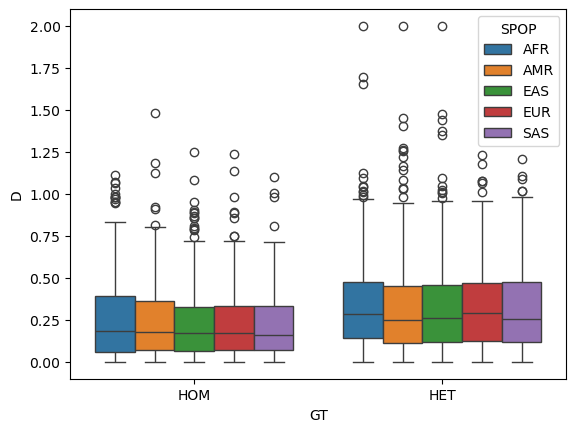

In [86]:
sns.boxplot(D_df, x="GT", y="D", hue="SPOP", hue_order=["AFR", "AMR", "EAS", "EUR", "SAS"])

In [87]:
D_df["D"].median()

np.float64(0.23251801744657463)

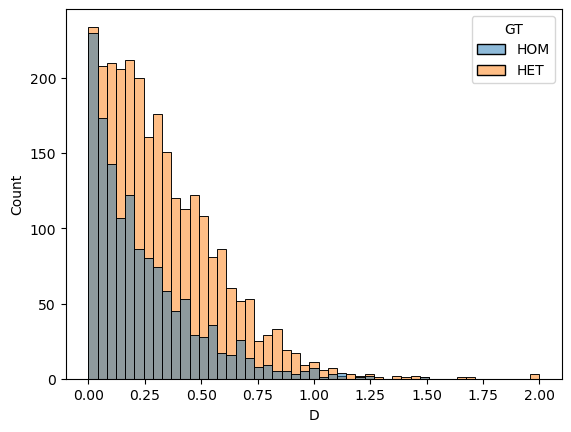

In [88]:
fig, ax = plt.subplots()
sns.histplot(D_df, x="D", hue="GT", ax=ax)
plt.savefig("plots/HOR_size_D.png")
plt.show()

In [89]:
D_df[D_df["GT"] == "HET"].describe()

,D
count,2731.000000
mean,0.322395
std,0.252480
min,0.000000
25%,0.126883
50%,0.270304
75%,0.468763
max,2.000000


In [90]:
D_df[D_df["GT"] == "HOM"].describe()

,D
count,1391.000000
mean,0.240747
std,0.227626
min,0.000000
25%,0.066853
50%,0.174789
75%,0.343617
max,1.480909
